In [341]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [342]:
df = pd.read_csv('churn_data.csv')

In [343]:
df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaN,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,...,0,lalita,India,Delhi,Female,1978-02-15,NaN,NaN,NaN,NaN
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,...,0,mohan,India,Nagaland,Male,2001-08-30,NaN,NaN,NaN,NaN
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,1,mira,India,Delhi,Female,1990-05-05,2024-01-20,Y,20.0,1.0
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaN,NaN,17.99,720,...,0,durga,NaN,Delhi,Female,1988-12-10,2025-03-18,N,90.0,1.0
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,...,1,mina,India,Meghalaya,Female,1976-09-21,2024-11-01,N,30.0,1.0
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaN,NaN,22.99,1840,...,0,madan,India,Rajasthan,Male,1999-03-14,NaN,NaN,NaN,NaN
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaN,NaN,13.99,240,...,0,maya,NaN,Kathmandu,Female,1985-07-07,NaN,NaN,NaN,NaN
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaN,NaN,6.99,335,...,0,arjun,Nepal,Kathmandu,Male,1993-10-29,NaN,NaN,NaN,NaN


In [344]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv',
       'churn_score', 'churn_flag', 'name', 'country', 'state', 'gender', 'dob', 'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [345]:
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate:",churn_rate.round(2), "%")

Churn Rate: 28.57 %


In [346]:
# Retention Rate
retention_rate = 100 - churn_rate
print("Retention Rate:",round(retention_rate,2),"%")

Retention Rate: 71.43 %


In [347]:
churn_by_plan = df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name = 'churn_rate_pct')

In [348]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv',
       'churn_score', 'churn_flag', 'name', 'country', 'state', 'gender', 'dob', 'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [349]:
revenue = df['monthly_charges'].sum().round(2)
print("Revenue: ", revenue)

Revenue:  395.79


In [350]:
# ARPU - avg rev per user
arpu = df['monthly_charges'].mean()
print('ARPU:', round(arpu,2))

ARPU: 18.85


In [351]:
df.groupby('state').agg(
    churn_percentage = ('churn_flag', lambda x: round(x.mean()*100,2)),
    total_revenue = ('monthly_charges', 'sum'),
    total_cust = ('customerid', 'count')
).reset_index().sort_values(by = 'total_revenue')

,state,churn_percentage,total_revenue,total_cust
1,Karnataka,100.00,20.98,2
2,Kathmandu,0.00,20.98,2
5,Nagaland,0.00,22.99,1
7,Telangana,50.00,30.98,2
6,Rajasthan,0.00,36.98,2
4,Meghalaya,66.67,42.97,3
3,Maharashtra,0.00,50.97,3
0,Delhi,25.00,52.96,4
8,Uttar Pradesh,0.00,115.98,2


In [352]:
df.groupby('subscription_type').agg(
    churn_percentage = ('churn_flag', lambda x : round(x.mean()*100,2)),
    total_revenue = ('monthly_charges', 'sum'),
    total_customers = ('customerid', 'count')
)

,churn_percentage,total_revenue,total_customers
subscription_type,,,
Organic,0.00,145.91,9
Paid,16.67,174.94,6
Refferal,83.33,74.94,6


In [353]:
cols = ['subscription_start_date', 'renewal_date', 'cancellation_date','complaint_date' ]

df[cols] = df[cols].apply(pd.to_datetime)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
 11  churn_flag               21 non-null     int64         
 12  name                     21 non-null     str     

In [354]:
today = pd.Timestamp.today()


df['tenure days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
    (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure days'].mean().round(2)
print("Average Tenure Days:", avg_tenure)

Average Tenure Days: 1558.71


In [355]:
#revenue at risk - Revenue loss by churned users 
revenue_at_risk = df.loc[df['churn_flag'] == 1,['monthly_charges']].sum()
print("Revenue at risk in (K) = ", revenue_at_risk)


Revenue at risk in (K) =  monthly_charges    73.94
dtype: float64


In [356]:
# Escalation Rate
EscalationRate = (df['escalations'] == 'Y').mean()*100
print("Escalation Rate = ", round(EscalationRate,2), "%")

Escalation Rate =  19.05 %


In [357]:
df['dob'] = pd.to_datetime(df['dob'])
today = pd.Timestamp.today()
df['age'] = (today.year - df['dob'].dt.year)

In [358]:
# Avg Complaint per user
avg_complaint = df['complaint_count'].sum()/ df['customerid'].nunique()
print("Average Complaint = ",round(avg_complaint,2), "%")

Average Complaint =  0.43 %


In [359]:
df['escalations'] = np.where(
    df['escalations'] == 'Y', 1,0
)

In [360]:
corr_df = df[['escalations', 'churn_flag']].dropna()
correlation = corr_df['escalations'].corr(corr_df['churn_flag'])*100
print("Correlation b/w Escalations & Churn_Flag:", round(correlation,2))

Correlation b/w Escalations & Churn_Flag: 76.7


In [361]:
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 200)

In [362]:
pd.reset_option('display.max_columns')
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure days,age
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,India,Maharashtra,Male,1982-04-12,NaT,0,NaN,NaN,2037.0,44
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,India,Karnataka,Male,1995-11-23,2024-08-28,1,10.0,2.0,1501.0,31
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,India,Delhi,Female,1978-02-15,NaT,0,NaN,NaN,1422.0,48
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,India,Nagaland,Male,2001-08-30,NaT,0,NaN,NaN,2712.0,25
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,India,Delhi,Female,1990-05-05,2024-01-20,1,20.0,1.0,419.0,36


In [363]:
# df['churn_score'].head()
# df['churn_risk'] = pd.cut(
#     df['churn_score'],
#     bins = [0,50,70,100],
#     labels=['low','med','high']
# )

# df[['churn_score','churn_risk']].head()
# df[['churn_score','churn_risk']].tail()


conditions = [
    df['churn_score'] <= 50,
    (df['churn_score'] > 50 )& (df['churn_score'] <= 70),
    df['churn_score'] > 70
]

labels = ['low','med','high']

df['churn_risk'] = np.select(conditions,labels,default = 'unknown')


In [364]:
df[['churn_score','churn_risk']].tail()

,churn_score,churn_risk
16,62,med
17,27,low
18,99,high
19,7,low
20,47,low


# Visualisation

In [365]:
df_copy = df.copy()

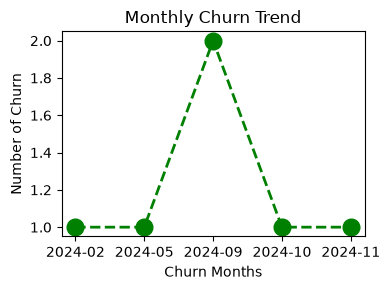

In [366]:
# Monthly Churn Rate
df_copy['cancellation_month'] = df_copy['cancellation_date'].dt.to_period('M')
churn_trend = df_copy[df_copy['churn_flag'] == 1].groupby(df_copy['cancellation_month']).size()

plt.figure(figsize=(4,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values, color = 'green', linewidth=2, marker ='o', linestyle = 'dashed', markersize = 12)
plt.title('Monthly Churn Trend')
plt.xlabel('Churn Months')
plt.ylabel('Number of Churn')
plt.tight_layout()

<Axes: xlabel='plan_type'>

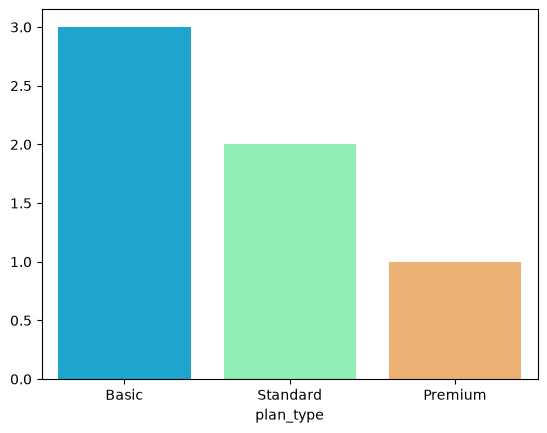

In [367]:
# Churn by plan-type
plan_type_churn = df_copy[df_copy['churn_flag'] == 1].groupby('plan_type').size().sort_values(ascending=False)
sns.barplot(x = plan_type_churn.index,y = plan_type_churn.values, palette='rainbow')


([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, 'Karnataka'),
  Text(1, 0, 'Meghalaya'),
  Text(2, 0, 'Delhi'),
  Text(3, 0, 'Telangana'),
  Text(4, 0, 'Kathmandu'),
  Text(5, 0, 'Maharashtra'),
  Text(6, 0, 'Nagaland'),
  Text(7, 0, 'Rajasthan'),
  Text(8, 0, 'Uttar Pradesh')])

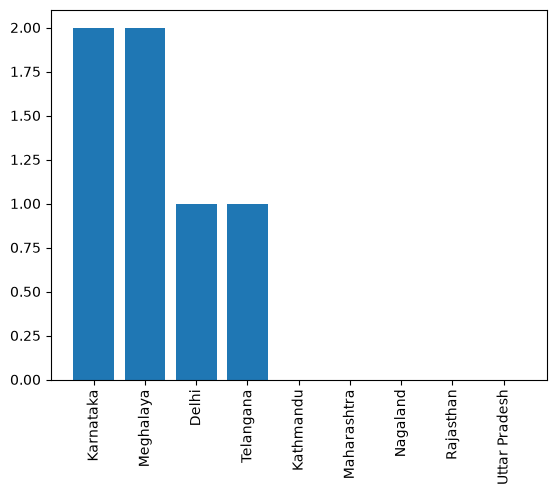

In [368]:
# Churn by states
churn_state = df_copy.groupby('state')['churn_flag'].sum().sort_values(ascending=False)

plt.bar(churn_state.index, churn_state.values)
plt.xticks(rotation = 90)

<Axes: >

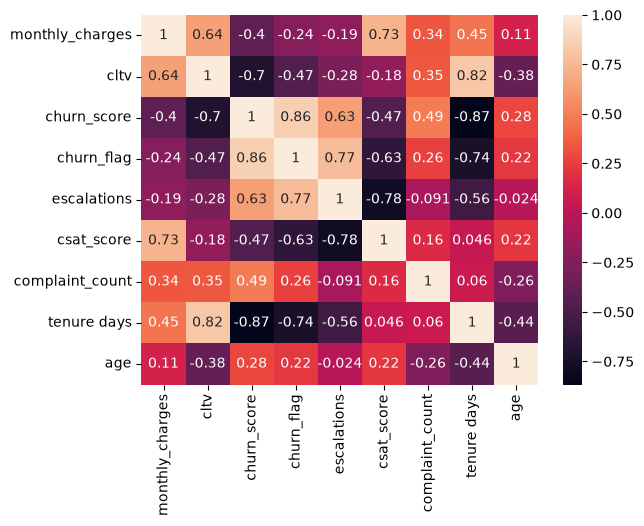

In [369]:
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True)

In [370]:
df_encode = df_copy[['plan_type','contract_type','churn_risk', 'escalations','churn_flag', 'churn_score']]

df_encode['plan_type']=df_copy['plan_type'].map({
    'Basic' : 0,
    'Standard' : 1,
    'Premium' : 2
})

df_encode['contract_type'] = df_copy['contract_type'].map({
    'Monthly' : 0,
    'Annual' : 1
})
df_encode['churn_risk'] = df_copy['churn_risk'].map({
    'low' : 0,
    'med' : 1,
    'high' : 2
})

<Axes: >

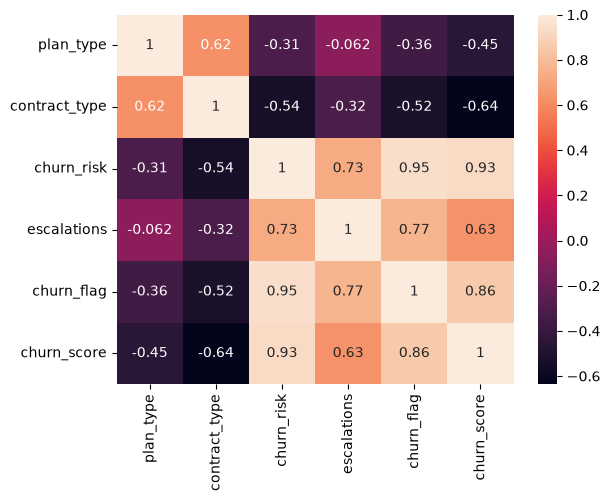

In [371]:
cols = df_encode[['plan_type','contract_type','churn_risk', 'escalations','churn_flag', 'churn_score']]
sns.heatmap(cols.corr(), annot=True)

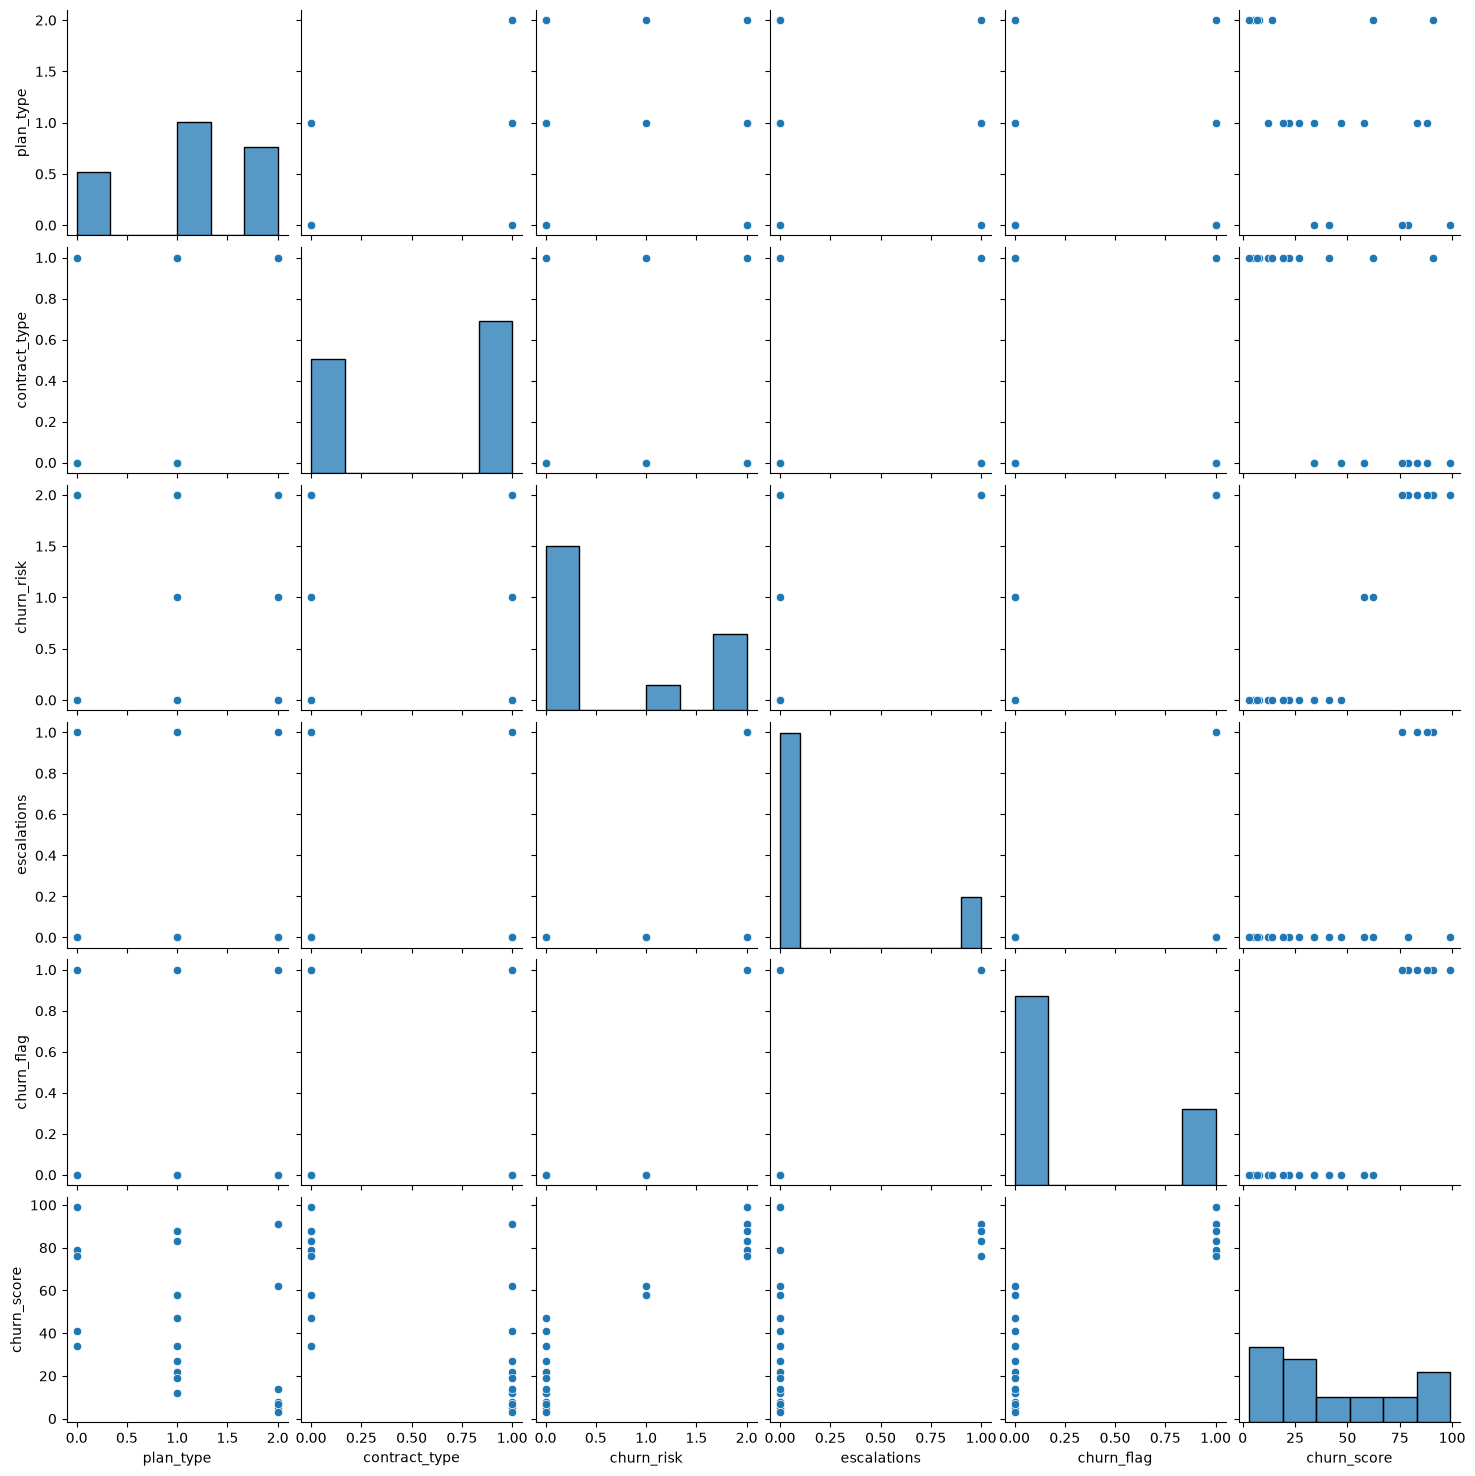

In [372]:
sns.pairplot(cols)

In [373]:
df_copy.columns

Index(['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv',
       'churn_score', 'churn_flag', 'name', 'country', 'state', 'gender', 'dob', 'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'tenure days', 'age', 'churn_risk',
       'cancellation_month'],
      dtype='str')

([0, 1, 2],
 [Text(0, 0, 'Standard'), Text(1, 0, 'Premium'), Text(2, 0, 'Basic')])

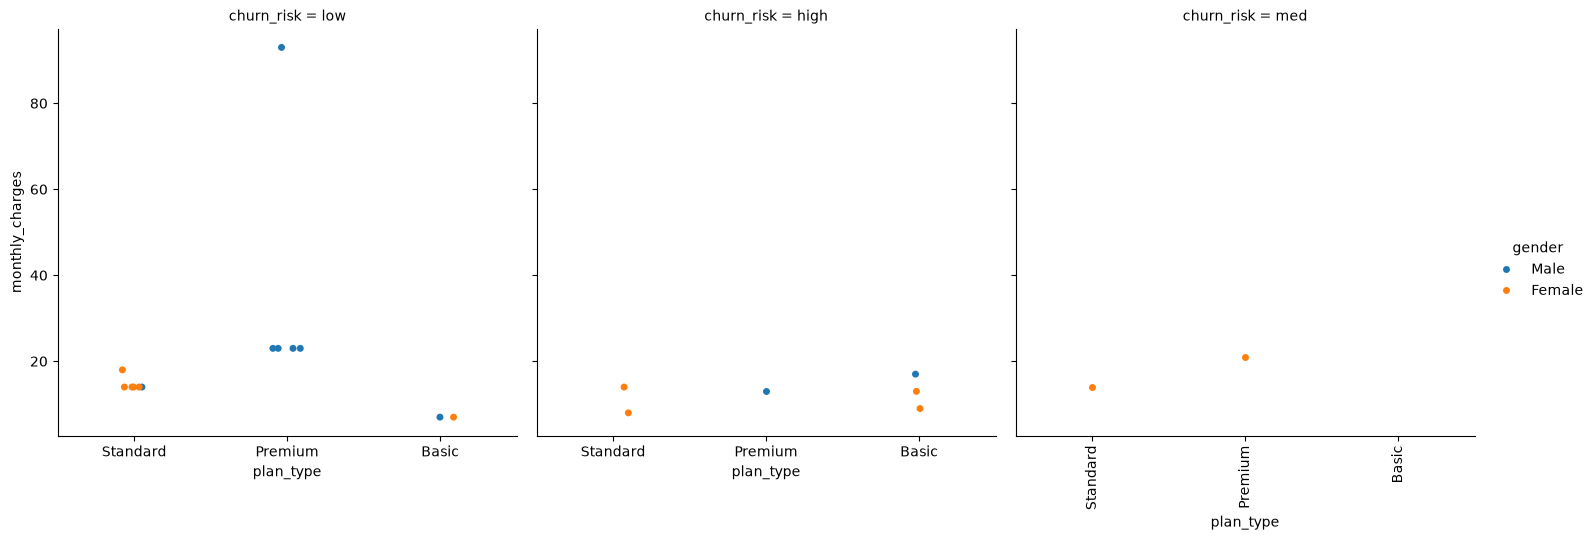

In [374]:
sns.catplot(data = df_copy,x = 'plan_type', y = 'monthly_charges', hue = 'gender', col = 'churn_risk')
plt.xticks(rotation = 90)

# Pivot Table

In [378]:
pd.pivot_table(
    data=df_copy,
    index='plan_type',
    values=['monthly_charges','customerid','churn_flag'],
    aggfunc={
        'monthly_charges' : 'sum',
        'customerid' : 'count',
        'churn_flag' : 'mean',
    }
).sort_values(by='monthly_charges', ascending=False)

,churn_flag,customerid,monthly_charges
plan_type,,,
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91
Basic,0.600000,5,52.95


# Working with SQL in python (pandas)

In [379]:
conn = sqlite3.connect('database.sqlite')

In [ ]:
conn.execute("CREATE TABLE USERS (First_name TEXT, Country TEXT, Budget INTERGER)")


OperationalError: table USERS already exists

In [382]:
conn.commit()

In [385]:
cursor = conn.cursor()

cursor.execute(
    """
    insert into users values
        ('Madhav', 'India', 5000),
        ('Abdullah', 'Dubai', 15000),
        ('Aqsa', 'India', 25000)
    
"""
               )

conn.commit()

In [388]:
# check inserted data in table

conn = sqlite3.connect('database.sqlite')
query = """select * from users"""

df_database = pd.read_sql(query,conn)
df_database


,First_name,Country,Budget
0,Madhav,India,5000
1,Abdullah,Dubai,15000
2,Aqsa,India,25000


In [390]:
#aggregation

query = """select country, sum(budget) as total_budget
            from users
            group by country
 """
df_agg = pd.read_sql(query,conn)
df_agg

,Country,total_budget
0,Dubai,15000
1,India,30000


In [391]:
conn.close()